In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def bins_create(x):
    if x <= 50:
        return 'small'
    if x <= 200:
        return 'medium'
    if x <= 1000:
        return 'high'
    else:
        return 'large'

### Linear regression

In [5]:
df_linear = pd.read_csv(r'output\history\boltzmann_csrnet\linear_regression_test_results.csv')
df_linear = df_linear[df_linear['gt'] != 0]
df_linear['mse'] = df_linear['abs_err'] ** 2
df_linear_grouped = df_linear.groupby('dataset').mean()
df_linear_grouped['rmse'] = np.sqrt(df_linear_grouped['mse'])
df_linear_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,201.042469,246.584131,28.991971
ShanghaiTech_part_A,583.096792,881.399646,0.596750
ShanghaiTech_part_B,143.461268,174.423481,2.023500
UCF-QNRF_ECCV18,365.121837,582.981362,5.850611
jhu_crowd_v2.0,319.774962,594.686747,8.295111
ucf-cc-50,1524.767171,2212.218034,0.658407


Text(0, 0.5, 'Predicted')

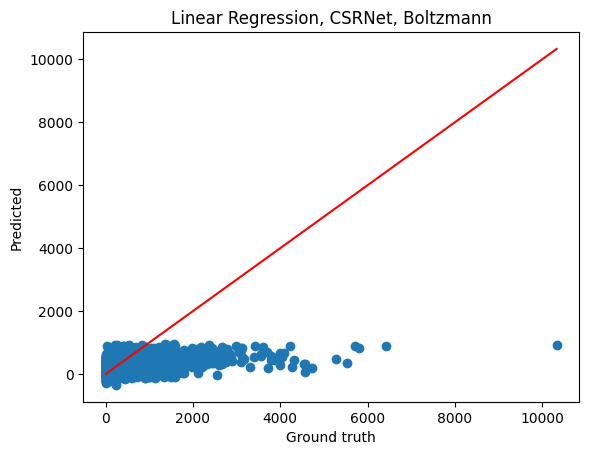

In [6]:
plt.scatter(df_linear['gt'], df_linear['pred'])
plt.plot([0,max(df_linear['gt'])], [0, max(df_linear['gt'])], color='red')
plt.title('Linear Regression, CSRNet, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [7]:
df_linear['bins'] = df_linear['gt'].apply(lambda x: bins_create(x))
df_linear.drop(columns='dataset', inplace=True)
df_linear = df_linear.groupby(['bins']).mean()
df_linear['rmse'] = np.sqrt(df_linear['mse'])
df_linear[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,255.100079,321.679874,0.568213
large,1544.974891,1883.867832,0.747749
medium,174.428780,219.775724,1.903846
small,191.258812,232.680555,29.715264


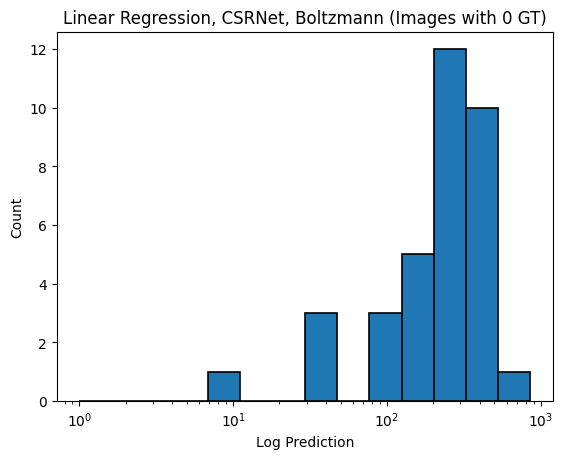

In [9]:
df_linear = pd.read_csv(r'output\history\boltzmann_csrnet\linear_regression_test_results.csv')
df_linear = df_linear[df_linear['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_linear['pred'].max()),
    15
)

plt.hist(
    df_linear['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Linear Regression, CSRNet, Boltzmann (Images with 0 GT)")

plt.show()

### SVM

In [10]:
df_svm = pd.read_csv(r'output\history\boltzmann_csrnet\svm_test_results.csv')
df_svm = df_svm[df_svm['gt'] != 0]
df_svm['mse'] = df_svm['abs_err'] ** 2
df_svm_grouped = df_svm.groupby('dataset').mean()
df_svm_grouped['rmse'] = np.sqrt(df_svm_grouped['mse'])
df_svm_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,53.682978,85.713218,7.799312
ShanghaiTech_part_A,796.134264,1084.973148,0.860970
ShanghaiTech_part_B,83.396823,127.875311,0.556377
UCF-QNRF_ECCV18,280.540213,638.998743,1.359982
jhu_crowd_v2.0,323.373486,677.616487,2.498784
ucf-cc-50,1934.863703,2575.245585,0.911606


Text(0, 0.5, 'Predicted')

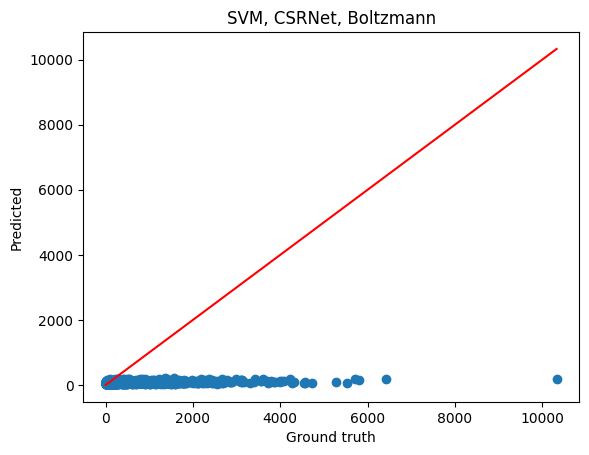

In [11]:
plt.scatter(df_svm['gt'], df_svm['pred'])
plt.plot([0,max(df_svm['gt'])], [0, max(df_svm['gt'])], color='red')
plt.title('SVM, CSRNet, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [12]:
df_svm['bins'] = df_svm['gt'].apply(lambda x: bins_create(x))
df_svm.drop(columns='dataset', inplace=True)
df_svm = df_svm.groupby(['bins']).mean()
df_svm['rmse'] = np.sqrt(df_svm['mse'])
df_svm[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,384.047129,439.744551,0.809377
large,1893.932564,2197.604886,0.946361
medium,49.406026,63.474928,0.392799
small,38.226481,42.884150,7.850962


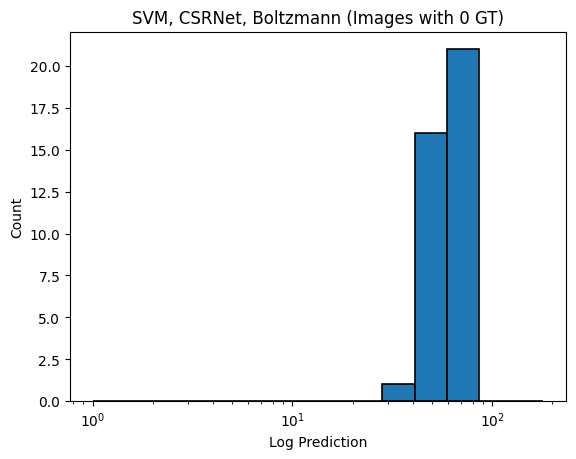

In [14]:
df_svm = pd.read_csv(r'output\history\boltzmann_csrnet\svm_test_results.csv')
df_svm = df_svm[df_svm['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_svm['pred'].max()),
    15
)

plt.hist(
    df_svm['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("SVM, CSRNet, Boltzmann (Images with 0 GT)")

plt.show()

### Decision Tree

In [15]:
df_tree = pd.read_csv(r'output\history\boltzmann_csrnet\decision_tree_test_results.csv')
df_tree = df_tree[df_tree['gt'] != 0]
df_tree['mse'] = df_tree['abs_err'] ** 2
df_tree_grouped = df_tree.groupby('dataset').mean()
df_tree_grouped['rmse'] = np.sqrt(df_tree_grouped['mse'])
df_tree_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,284.560454,652.033678,35.447267
ShanghaiTech_part_A,811.945256,1350.103826,1.065847
ShanghaiTech_part_B,286.643862,653.007777,3.346149
UCF-QNRF_ECCV18,544.570903,1233.822277,10.608978
jhu_crowd_v2.0,475.934286,866.086307,11.543468
ucf-cc-50,1879.465983,2555.450018,0.922397


Text(0, 0.5, 'Predicted')

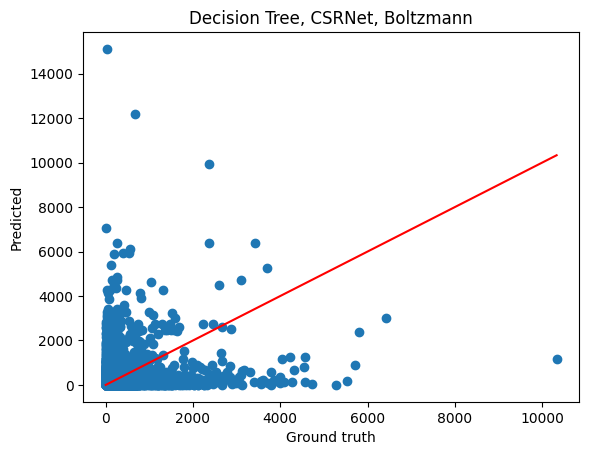

In [16]:
plt.scatter(df_tree['gt'], df_tree['pred'])
plt.plot([0,max(df_tree['gt'])], [0, max(df_tree['gt'])], color='red')
plt.title('Decision Tree, CSRNet, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [17]:
df_tree['bins'] = df_tree['gt'].apply(lambda x: bins_create(x))
df_tree.drop(columns='dataset', inplace=True)
df_tree = df_tree.groupby(['bins']).mean()
df_tree['rmse'] = np.sqrt(df_tree['mse'])
df_tree[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,520.063268,927.012860,1.299611
large,1719.859314,2048.071985,0.877430
medium,271.026101,583.226403,2.868229
small,290.346325,782.267242,39.329858


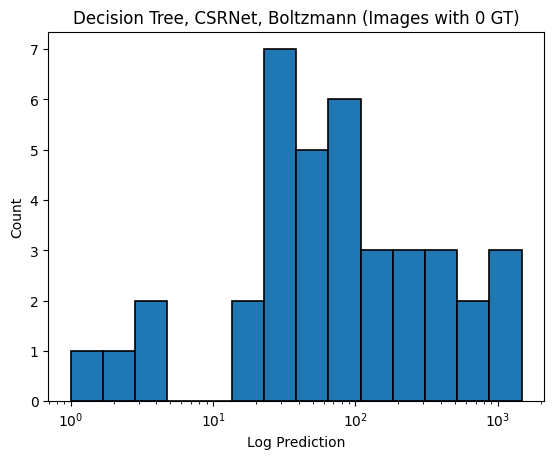

In [19]:
df_tree = pd.read_csv(r'output\history\boltzmann_csrnet\decision_tree_test_results.csv')
df_tree = df_tree[df_tree['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_tree['pred'].max()),
    15
)

plt.hist(
    df_tree['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Decision Tree, CSRNet, Boltzmann (Images with 0 GT)")

plt.show()

### Random forrest

In [20]:
df_rf = pd.read_csv(r'output\history\boltzmann_csrnet\random_forest_test_results.csv')
df_rf = df_rf[df_rf['gt'] != 0]
df_rf['mse'] = df_rf['abs_err'] ** 2
df_rf_grouped = df_rf.groupby('dataset').mean()
df_rf_grouped['rmse'] = np.sqrt(df_rf_grouped['mse'])
df_rf_grouped[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
dataset,,,
NWPU-Crowd,304.498613,337.319116,45.236216
ShanghaiTech_part_A,524.019759,807.239486,0.550894
ShanghaiTech_part_B,210.917752,245.847745,3.435364
UCF-QNRF_ECCV18,405.862754,585.900062,8.571986
jhu_crowd_v2.0,355.895907,600.061646,13.948359
ucf-cc-50,1410.287557,2096.440348,0.627110


Text(0, 0.5, 'Predicted')

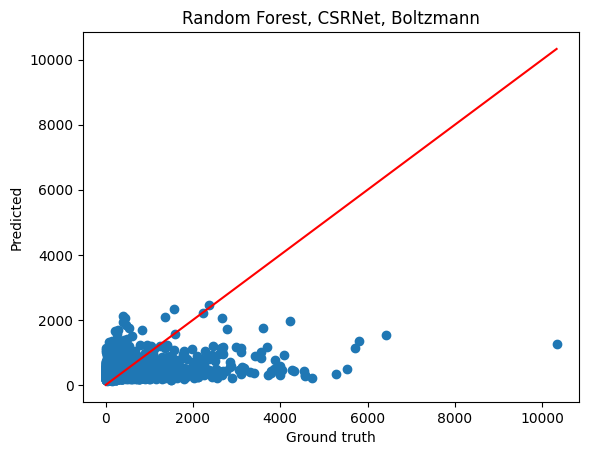

In [21]:
plt.scatter(df_rf['gt'], df_rf['pred'])
plt.plot([0,max(df_rf['gt'])], [0, max(df_rf['gt'])], color='red')
plt.title('Random Forest, CSRNet, Boltzmann')
plt.xlabel('Ground truth')
plt.ylabel('Predicted')

In [22]:
df_rf['bins'] = df_rf['gt'].apply(lambda x: bins_create(x))
df_rf.drop(columns='dataset', inplace=True)
df_rf = df_rf.groupby(['bins']).mean()
df_rf['rmse'] = np.sqrt(df_rf['mse'])
df_rf[['abs_err', 'rmse', 'perc']]

,abs_err,rmse,perc
bins,,,
high,225.003974,317.823206,0.520401
large,1431.358186,1786.611686,0.685927
medium,251.753992,302.326096,2.831934
small,311.569262,335.617639,48.546088


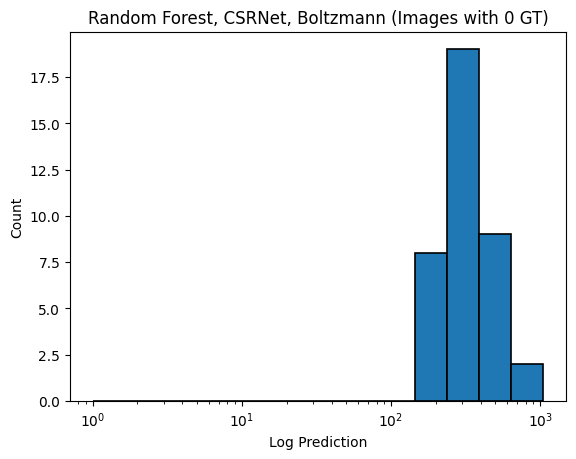

In [23]:
df_rf = pd.read_csv(r'output\history\boltzmann_csrnet\random_forest_test_results.csv')
df_rf = df_rf[df_rf['gt'] == 0]

bins = np.logspace(
    0,
    np.log10(df_rf['pred'].max()),
    15
)

plt.hist(
    df_rf['pred'],
    bins=bins,
    edgecolor='black',
    linewidth=1.2
)

plt.xscale('log')

plt.xlabel("Log Prediction")
plt.ylabel("Count")
plt.title("Random Forest, CSRNet, Boltzmann (Images with 0 GT)")

plt.show()